In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Вариант № 7 Квадратичный конгруэнтный метод, формула (1.18)

##### Начальные данные:
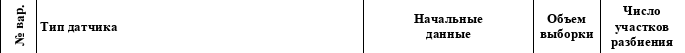
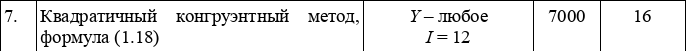


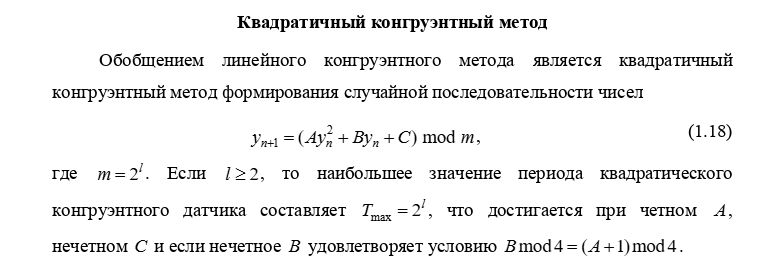

In [ ]:
class QCM:
    def __init__(self, A=6, B=7, C=3, Mm=4096, Y=4001):
        
        self.A = A
        self.B = B
        self.C = C
        self._Mm = Mm        # модуль генератора
        self._Y = Y          # начальное значение
        self._N = 7000       # объём выборки 

        # проверка условия максимального периода
        if not (B % 4 == (A + 1) % 4
                and A % 2 == 0
                and C % 2 != 0
                and B % 2 != 0):
            raise ValueError(
                "Коэффициенты не удовлетворяют условию:\n"
                "  B mod 4 == (A+1) mod 4\n"
                "  A — чётное\n"
                "  C — нечётное\n"
                "  B — нечётное"
            )
    
    def _funk(self):
        self._Y = (self.A * self._Y * self._Y
                   + self.B * self._Y
                   + self.C) % self._Mm
        return self._Y / self._Mm
    
    def generate(self):
        return np.array([self._funk() for _ in range(self._N)])
    
    def estimate(self, x):
        """Считает статистические оценки."""
        N = len(x)
        mean_est = np.mean(x)
        m2_est = np.mean(x**2)
        m3_est = np.mean(x**3)
        var_est = m2_est - mean_est**2                # Выборочная (смещённая) дисперсия
        var_unbiased = var_est * N / (N - 1)          # Исправленная (несмещённая) дисперсия
        skew_est = np.mean((x - mean_est)**3) / (np.std(x)**3) # Асимметрия
        return {
            "mean": mean_est,
            "var": var_est,
            "var_unbiased": var_unbiased,
            "m2": m2_est,
            "m3": m3_est,
            "skew": skew_est,
        }
    
    def plot(self, x, K=16):
        """Строит гистограмму частот и эмпирическую CDF."""
        fig, axes = plt.subplots(1, 2, figsize=(13, 5))

        # --- Гистограмма (нормализованная) ---
        counts, edges = np.histogram(x, bins=K, range=(0, 1), density=True)
        centers = (edges[:-1] + edges[1:]) / 2
        axes[0].bar(centers, counts, width=1/K,
                    edgecolor='black', alpha=0.75, label='Гистограмма')
        axes[0].axhline(y=1, color='r', linestyle='--',
                        label='Теоретическая плотность = 1')
        axes[0].set_xlabel('x')
        axes[0].set_ylabel('Плотность частоты')
        axes[0].set_title(f'Нормализованная гистограмма (K={K})')
        axes[0].legend()
        axes[0].grid(alpha=0.3)

        # --- Эмпирическая функция распределения ---
        x_sorted = np.sort(x)
        cdf_emp = np.arange(1, len(x) + 1) / len(x)
        axes[1].step(x_sorted, cdf_emp, where='post',
                     label='Эмпирическая CDF')
        xx = np.linspace(0, 1, 200)
        axes[1].plot(xx, xx, 'r--', label='Теоретическая CDF: F(x)=x')
        axes[1].set_xlabel('x')
        axes[1].set_ylabel('F(x)')
        axes[1].set_title('Статистическая функция распределения')
        axes[1].legend()
        axes[1].grid(alpha=0.3)

        plt.tight_layout()
        plt.show()

##### Создание генератора и генерация выборки

In [3]:
gen = QCM(A=6, B=7, C=3, Mm=4096, Y=4001)
x = gen.generate()

print(f"Сгенерировано чисел: {len(x)}")
print(f"Первые 10 чисел: {x[:10]}")
print(f"Минимум: {x.min():.4f}, Максимум: {x.max():.4f}")

Сгенерировано чисел: 7000
Первые 10 чисел: [0.05859375 0.78588867 0.15576172 0.34692383 0.30175781 0.94897461
 0.62939453 0.88110352 0.58398438 0.43237305]
Минимум: 0.0000, Максимум: 0.9998


##### Статистические оценки

In [4]:
est = gen.estimate(x)

print("Статистические оценки (N = 7000):")
print(f"  Выборочное среднее:        {est['mean']:.6f}   (теор. 0.500000)")
print(f"  Выборочная дисперсия:      {est['var']:.6f}   (теор. 0.083333)")
print(f"  Исправленная дисперсия:    {est['var_unbiased']:.6f}")
print(f"  Второй начальный момент:   {est['m2']:.6f}   (теор. 0.333333)")
print(f"  Третий начальный момент:   {est['m3']:.6f}   (теор. 0.250000)")
print(f"  Асимметрия:                {est['skew']:.6f}   (теор. 0.000000)")

Статистические оценки (N = 7000):
  Выборочное среднее:        0.502188   (теор. 0.500000)
  Выборочная дисперсия:      0.083232   (теор. 0.083333)
  Исправленная дисперсия:    0.083243
  Второй начальный момент:   0.335425   (теор. 0.333333)
  Третий начальный момент:   0.251704   (теор. 0.250000)
  Асимметрия:                -0.014063   (теор. 0.000000)


#####

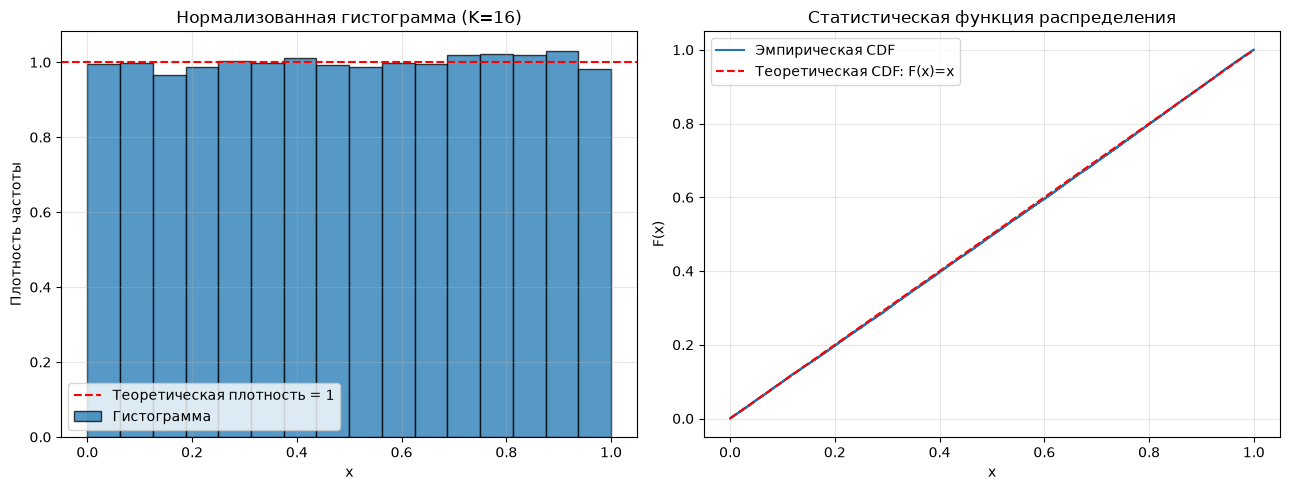

In [6]:
gen.plot(x, K=16) 